<a href="https://colab.research.google.com/github/piihutanoch/pet-breed-classifier/blob/main/notebooks/06_package.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# GitHub account name used in the README links, the model download URL and the resume
GITHUB_USERNAME = "piihutanoch"

### GitHub Username

Defines the GitHub username used for the repository link, the model download URL and the resume entry. An assertion stops the notebook if the placeholder has not been replaced.

In [2]:
# Install Grad-CAM and Gradio (not preinstalled on Colab)
!pip install -q grad-cam gradio

# Mount Google Drive to access the project folder
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, sys, shutil, importlib, time, os
import pandas as pd
from importlib.metadata import version

# Project paths: v2 artifacts and a folder for README images
project_dir = Path("/content/drive/MyDrive/pet-breed-classifier")
artifacts_dir = project_dir / "artifacts_v2"    # v2 (137 breeds); v1 is kept in artifacts/
assets_dir = project_dir / "assets"
assets_dir.mkdir(exist_ok=True)
sys.path.append(str(project_dir))    # Make src/ importable

# Load the saved evaluation results and model configuration
with open(artifacts_dir / "metrics.json") as f:
    metrics = json.load(f)
with open(artifacts_dir / "model_config.json") as f:
    config = json.load(f)
print(json.dumps(metrics, indent=2))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
{
  "model": "resnet50",
  "n_test": 3784,
  "test_acc": 0.8903,
  "top5_acc": 0.9852,
  "macro_f1": 0.8855,
  "cat_acc": 0.9438,
  "dog_acc": 0.8848,
  "baseline_test_acc": 0.7447,
  "threshold": 0.45,
  "nonpet_rejected": 28,
  "nonpet_total": 28,
  "pets_wrongly_rejected": 0.0368
}


### Setup and Loading Saved Results

Installs the required libraries, mounts Google Drive and defines the project paths.

- `artifacts_dir` points to `artifacts_v2/`, which contains the final 137-breed model and all of its evaluation results.
- `assets_dir` stores the images used in the GitHub README.
- `metrics.json` and `model_config.json` are loaded so that every number in the README and resume is read from the saved results instead of being typed by hand.
- If `threshold` or `nonpet_rejected` are missing from the printed metrics, the threshold cell in `05_app_dev` has not been run.

In [3]:
# Return the installed version of a package without the build suffix
def v(pkg):
    return version(pkg).split("+")[0]        # "2.8.0+cu126" -> "2.8.0"

# Pin every package to the version tested in Colab; use CPU-only PyTorch builds
requirements = f"""--extra-index-url https://download.pytorch.org/whl/cpu
torch=={v('torch')}+cpu
torchvision=={v('torchvision')}+cpu
gradio=={v('gradio')}
grad-cam=={v('grad-cam')}
pandas=={v('pandas')}
pillow=={v('pillow')}
matplotlib=={v('matplotlib')}
numpy=={v('numpy')}
"""
print(requirements)

--extra-index-url https://download.pytorch.org/whl/cpu
torch==2.14.1+cpu
torchvision==0.29.1+cpu
gradio==6.31.0
grad-cam==1.5.7
pandas==2.2.3
pillow==11.3.0
matplotlib==3.10.0
numpy==2.4.6



### Creating requirements.txt with Pinned Versions

Generates the list of Python packages needed to run the app, used when running it locally and later in Shiro's backend.

- **Pinned versions (`==`):** each package is fixed to the exact version tested in Colab. Without pinning, a fresh install would pick up the newest versions, and a future release could break the app without any code changes.
- **CPU-only PyTorch:** `--extra-index-url https://download.pytorch.org/whl/cpu` and the `+cpu` suffix install the CPU builds of `torch` and `torchvision`. The default builds include over 2 GB of GPU libraries that are not needed for CPU inference.
- `v()` removes the build suffix from Colab's version strings (e.g. `2.8.0+cu126` → `2.8.0`) so `+cpu` can be added instead.

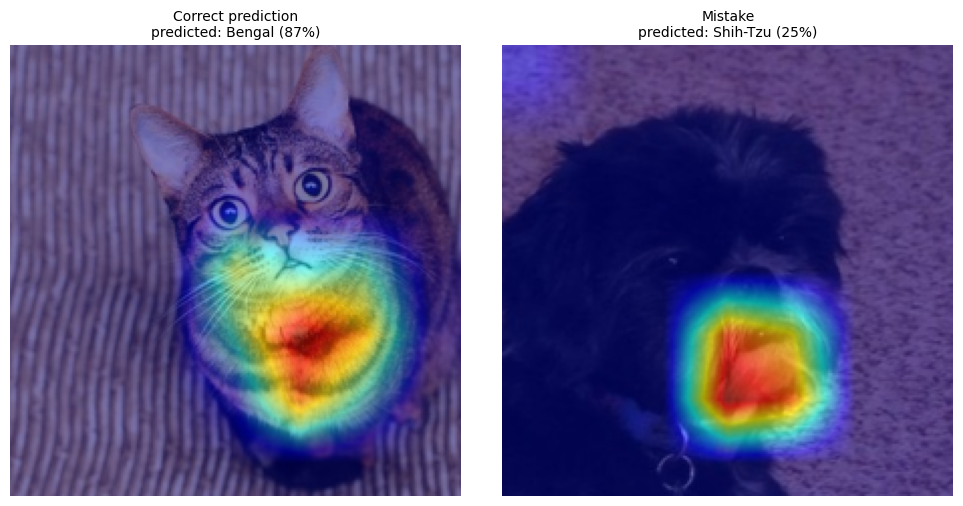

CPU time for prediction + Grad-CAM: ~1.4 s per image


In [4]:
# Reload project modules to use their latest versions
import src.data, src.model, src.predict, src.gradcam
for m in [src.data, src.model, src.predict, src.gradcam]:
    importlib.reload(m)
from src.predict import load_model, predict
from src.gradcam import gradcam_overlay
from PIL import Image
import matplotlib.pyplot as plt

# Load the final model on CPU, as it will run on a typical CPU-only server
model, classes, model_name = load_model(artifacts_dir)

# One correctly classified example image
correct_img = sorted((artifacts_dir / "examples").glob("*.jpg"))[0]
# Most-confused pair from Day 4 (Shih-Tzu → Lhasa in v2)
top_pair = pd.read_csv(artifacts_dir / "confused_pairs.csv").iloc[0]
prefix = f"{top_pair['true']}__{top_pair['predicted']}__".replace(" ", "_")
mistake_img = sorted((artifacts_dir / "errors").glob(prefix + "*.jpg"))[0]

# Time prediction + Grad-CAM for each image and plot the heatmaps side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
times = []
for ax, path, title in zip(axes, [correct_img, mistake_img], ["Correct prediction", "Mistake"]):
    img = Image.open(path)
    start = time.time()
    best_breed, best_prob = predict(model, classes, img, k=1)[0]
    overlay = gradcam_overlay(model, model_name, img, classes.index(best_breed))
    times.append(time.time() - start)
    ax.imshow(overlay)
    ax.set_title(f"{title}\npredicted: {best_breed} ({best_prob:.0%})", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig(assets_dir / "gradcam_examples.png", dpi=120)
plt.show()

infer_secs = round(max(times), 1)            # report the slower one (honest)
print(f"CPU time for prediction + Grad-CAM: ~{infer_secs} s per image")

### Grad-CAM Figure and CPU Inference Time

Creates a Grad-CAM figure for the README and measures how long the app takes per image.

- Selects one correctly classified example image and one mistake from the most frequently confused breed pair (Shih-Tzu → Lhasa).
- Runs prediction and Grad-CAM for each image and records the total time on CPU, matching a typical CPU-only server.
- Saves the figure to `assets/gradcam_examples.png`.
- `infer_secs` stores the slower of the two times, so the reported speed is not optimistic.

In [5]:
app_dir = Path("/content/app_bundle")
if app_dir.exists():
    shutil.rmtree(app_dir)                  # start clean every time
(app_dir / "src").mkdir(parents=True)
(app_dir / "artifacts_v2").mkdir()          # app.py and predict.py load from artifacts_v2/

# Code
shutil.copy(project_dir / "app.py", app_dir)
for f in ["data.py", "model.py", "predict.py", "gradcam.py"]:
    shutil.copy(project_dir / "src" / f, app_dir / "src")

# Only the artifacts app.py actually loads
for f in ["model.pt", "model_config.json", "classes.json", "metrics.json",
          "per_class.csv", "confused_pairs.csv", "confusion.png", "accuracy_by_source.csv"]:
    shutil.copy(artifacts_dir / f, app_dir / "artifacts_v2")
shutil.copytree(artifacts_dir / "examples", app_dir / "artifacts_v2" / "examples")
shutil.copytree(artifacts_dir / "errors", app_dir / "artifacts_v2" / "errors")

# Python packages + Linux packages
(app_dir / "requirements.txt").write_text(requirements)
(app_dir / "packages.txt").write_text("libgl1\nlibglib2.0-0\n")

# List the files and total size of the app bundle
!find /content/app_bundle -type f | sort
!du -sh /content/app_bundle

/content/app_bundle/app.py
/content/app_bundle/artifacts_v2/accuracy_by_source.csv
/content/app_bundle/artifacts_v2/classes.json
/content/app_bundle/artifacts_v2/confused_pairs.csv
/content/app_bundle/artifacts_v2/confusion.png
/content/app_bundle/artifacts_v2/errors/American_Staffordshire_Terrier__Staffordshire_Bull_Terrier__0.jpg
/content/app_bundle/artifacts_v2/errors/American_Staffordshire_Terrier__Staffordshire_Bull_Terrier__1.jpg
/content/app_bundle/artifacts_v2/errors/American_Staffordshire_Terrier__Staffordshire_Bull_Terrier__2.jpg
/content/app_bundle/artifacts_v2/errors/American_Staffordshire_Terrier__Staffordshire_Bull_Terrier__3.jpg
/content/app_bundle/artifacts_v2/errors/Collie__Border_Collie__0.jpg
/content/app_bundle/artifacts_v2/errors/Collie__Border_Collie__1.jpg
/content/app_bundle/artifacts_v2/errors/Collie__Border_Collie__2.jpg
/content/app_bundle/artifacts_v2/errors/Collie__Border_Collie__3.jpg
/content/app_bundle/artifacts_v2/errors/English_Foxhound__Walker_Hound__

### Building the App Bundle

Collects only the files the app needs to run into `/content/app_bundle`.

- **Code:** `app.py` and the `src/` modules used for preprocessing, model loading, prediction and Grad-CAM.
- **Artifacts:** the final `model.pt`, its configuration, class names, metrics, per-breed and per-source results, confused pairs, the confusion matrix, example images and error images. They are kept in `artifacts_v2/`, where `app.py` and `predict.py` look for them.
- **Excluded:** training checkpoints, histories, notebooks and all Indie (Pinterest) photos. Example images come from Oxford-IIIT Pet only.
- `requirements.txt` lists the Python packages; `packages.txt` lists the Linux packages `libgl1` and `libglib2.0-0`, which OpenCV (used by Grad-CAM) needs on a bare Linux server.
- The folder is deleted and rebuilt on every run so that no outdated files remain.

In [6]:
# Import app.py in a fresh Python process from inside the app bundle and classify one example image
!cd /content/app_bundle && python -c "\
import app, glob; \
from PIL import Image; \
img = Image.open(sorted(glob.glob('artifacts_v2/examples/*.jpg'))[0]); \
label, cam, msg = app.classify(img); \
print('OK:', msg.splitlines()[0], '| heatmap', cam.shape)"

  File "<string>", line 1
    import app, glob;  from PIL import Image;  img = Image.open(sorted(glob.glob('artifacts_v2/examples/*.jpg'))[0]);  label, cam, msg = app.classify(img);  print('OK:', msg.splitlines()[0], '| heatmap', cam.shape)
IndentationError: unexpected indent


### Smoke Test of the App Bundle

Checks that the app bundle works on its own.

- Starts a new Python process inside `/content/app_bundle`, so only the files in that folder are available.
- Imports `app.py`, which loads the model and all artifacts, then classifies one example image with `app.classify()`.
- Prints the predicted breed and the shape of the Grad-CAM heatmap.

This confirms that anyone who downloads the repository and the model weights can run the app, and that the same files can later be reused in Shiro's backend.

In [8]:
# Convert the screen recording of the dashboard (assets/demo.mp4) into a GIF for the README
demo_mp4 = assets_dir / "demo.mp4"
demo_gif = assets_dir / "demo.gif"

# Pass 1: build a colour palette from the video (gives much better GIF colours)
!ffmpeg -y -loglevel error -i "{demo_mp4}" -vf "fps=10,scale=900:-1:flags=lanczos,palettegen" /content/palette.png

# Pass 2: create the GIF using that palette (10 frames per second, 900 px wide, loops forever)
!ffmpeg -y -loglevel error -i "{demo_mp4}" -i /content/palette.png -lavfi "fps=10,scale=900:-1:flags=lanczos[x];[x][1:v]paletteuse" -loop 0 "{demo_gif}"

# GitHub displays GIFs inline; keep the file small so the README loads quickly
print(f"demo.gif: {demo_gif.stat().st_size / 1e6:.1f} MB")

demo.gif: 32.1 MB


### Creating the Demo GIF

Converts a short screen recording of the Gradio dashboard into a GIF shown at the top of the README, since the app is not hosted publicly.

- The recording (`assets/demo.mp4`) shows a prediction with its Grad-CAM heatmap, the Shih Tzu example, a non-pet photo marked "not confident", and the performance and error-explorer tabs.
- `ffmpeg` converts it in two passes: the first builds a colour palette from the video and the second uses it, which avoids the banded colours of a direct conversion.
- The GIF is reduced to 10 frames per second and 900 pixels wide. GitHub shows GIFs directly in the README, unlike MP4 files stored in the repository.
- If the GIF is larger than about 10 MB, a shorter recording or a smaller width (e.g. `scale=720`) keeps the README fast to load.

In [9]:
# Write 1–2 sentences after looking at the Grad-CAM figure above
GRADCAM_NOTE = "___ (where did the heatmaps focus, for the correct prediction and for the mistake?)"

# ---- Validation comparison table, from saved histories (Days 2–3) ----
runs = [("Baseline", "EfficientNet-B0", "Yes", "No", "baseline_history.json", "baseline_b0.pt"),
        ("Fine-tuned", "EfficientNet-B0", "No", "Yes", "history_efficientnet_b0.json", "finetuned_efficientnet_b0.pt"),
        ("Fine-tuned", "ResNet-50", "No", "Yes", "history_resnet50.json", "finetuned_resnet50.pt")]
val_rows = []
for run, backbone, frozen, aug, hist_file, ckpt in runs:
    if not (artifacts_dir / hist_file).exists():
        continue
    with open(artifacts_dir / hist_file) as f:
        h = json.load(f)
    val_rows.append(f"| {run} | {backbone} | {frozen} | {aug} | {max(h['val_acc']):.2%} | "
                    f"{sum(h['epoch_time']) / len(h['epoch_time']):.0f} | "
                    f"{os.path.getsize(artifacts_dir / ckpt) / 1e6:.1f} MB |")
val_table = "\n".join(val_rows)

# ---- Accuracy by image source (Day 4) ----
by_source = pd.read_csv(artifacts_dir / "accuracy_by_source.csv")
source_names = {"oxford": "Oxford-IIIT Pet", "stanford": "Stanford Dogs", "indie": "Indian Pariah (Indie)"}
source_table = "\n".join(
    f"| {source_names[r['source']]} | {r['n_test']:,} | {r['accuracy']:.1%} | {r['top5_acc']:.1%} |"
    for _, r in by_source.iterrows()
)

# ---- Top confused pairs ----
pairs = pd.read_csv(artifacts_dir / "confused_pairs.csv").head(5)
pairs_table = "\n".join(f"| {r['true']} | {r['predicted']} | {r['count']} |" for _, r in pairs.iterrows())

# ---- Rejection numbers (from Day 5), with blanks if missing ----
thr = f"{metrics['threshold']:.2f}" if "threshold" in metrics else "___"
nonpet = f"{metrics['nonpet_rejected']}/{metrics['nonpet_total']}" if "nonpet_rejected" in metrics else "___/___"
wrong_rej = f"{metrics['pets_wrongly_rejected']:.1%}" if "pets_wrongly_rejected" in metrics else "___%"

pretty_name = {"resnet50": "ResNet-50", "efficientnet_b0": "EfficientNet-B0"}[config["name"]]
repo_url = f"https://github.com/{GITHUB_USERNAME}/pet-breed-classifier"
model_url = f"{repo_url}/releases/download/v2_137_breeds/model.pt"

readme = f"""# 🐾 Pet Breed Classifier

Fine-tuned {pretty_name} that identifies **137 cat and dog breeds** from a photo, including breeds common in
India such as the Shih Tzu, Labrador and Indian Pariah (Indie) dog. It shows Grad-CAM explanations, says
"not confident" for non-pet or unfamiliar images, and includes an interactive error-analysis dashboard.

![Dashboard demo](assets/demo.gif)

## Results

Evaluated **once** on a held-out test set ({metrics['n_test']:,} images, 15% of the data, stratified by breed).

| Model | Test accuracy | Top-5 | Macro F1 |
|---|---|---|---|
| Frozen EfficientNet-B0 (baseline) | {metrics['baseline_test_acc']:.1%} | n/a | n/a |
| **Fine-tuned {pretty_name} (final)** | **{metrics['test_acc']:.1%}** | **{metrics['top5_acc']:.1%}** | **{metrics['macro_f1']:.3f}** |

Accuracy on cats: {metrics['cat_acc']:.1%} · dogs: {metrics['dog_acc']:.1%}

**By image source:**

| Source | Test images | Accuracy | Top-5 |
|---|---|---|---|
{source_table}

Stanford Dogs images come from ImageNet, which the backbone was pretrained on, so their score could be
optimistic. In practice they score *lower* than Oxford images, because Stanford's 120 dog breeds include
many near-identical breeds.

<details>
<summary>Validation comparison used for model selection</summary>

| Run | Backbone | Frozen | Augmentation | Val acc | s/epoch (T4) | Size |
|---|---|---|---|---|---|---|
{val_table}

</details>

## Versions

| Version | Breeds | Images | Test accuracy | Why |
|---|---|---|---|---|
| v1 | 37 | 7,349 | 92.5% | Oxford-IIIT Pet only |
| **v2** | **137** | **25,216** | **{metrics['test_acc']:.1%}** | Added Stanford Dogs and Indie photos after v1 failed on common Indian breeds |

v1 predicted a Shih Tzu as a Havanese (67%) because Shih Tzu was not one of its breeds. v2 predicts it
correctly at 95%. Accuracy is lower in v2 because the task is much harder (137 breeds instead of 37),
but the model covers the breeds real users actually have. v1 is preserved in the `v1_37_breeds` release.

## Approach

- **Data:** Oxford-IIIT Pet (37 breeds) + Stanford Dogs (120 breeds) + 101 Indian Pariah photos collected by hand. 21 breeds present in both public datasets were merged into one class each, broken images and exact/near-duplicate photos were removed (MD5 + perceptual hash), and each breed was capped at 250 images. Split 70/15/15 into train/val/test, **stratified by breed**, with a fixed seed. Indie photos were split by dog, so no dog appears in two splits.
- **Baseline:** EfficientNet-B0 pretrained on ImageNet, backbone frozen, new linear head (effectively logistic regression on pretrained features).
- **Fine-tuning:** all layers unfrozen, train-only augmentation (random resized crop, horizontal flip, colour jitter without hue), AdamW with a 10× lower learning rate for the backbone than the head, cosine schedule, label smoothing 0.1, early stopping.
- **Model selection on validation:** ResNet-50 was chosen only if it beat EfficientNet-B0 by more than 0.5 points, since it is 5.6× larger.
- **App:** a Gradio dashboard with live prediction, Grad-CAM, per-breed metrics and an error explorer. All metrics and plots are precomputed, so the app only runs single-image CPU inference (~{infer_secs} s including Grad-CAM).

## Error analysis

| True breed | Predicted as | Test images |
|---|---|---|
{pairs_table}

The biggest confusions are between closely related breeds that are hard to tell apart even for people:
Shih Tzus and Lhasa Apsos both have long facial hair, Siberian Huskies and Eskimo Dogs share coat and build,
and the three poodle sizes differ mainly in size, which a single photo cannot show. Cats score higher than
dogs in v2 because the dog classes now include all 120 Stanford breeds, many of them near-identical.

![Grad-CAM examples](assets/gradcam_examples.png)

{GRADCAM_NOTE}

## Confidence levels

The app uses three confidence levels. Below **40%**, it says the image might not be a cat or a dog: all
{nonpet} non-pet test photos scored below this. Between **40% and 50%**, it warns that the photo might be
unclear (or a mixed or unsupported breed) and shows the top 3 guesses. Above **50%**, it shows the breed.
For reference, the threshold tuned on validation to reject at most 5% of correct predictions was **{thr}**
(it wrongly rejects {wrong_rej} of correctly classified test pets).

## Limitations

- Knows **only these 137 breeds**: mixed breeds and other breeds get the closest-looking match.
- The confidence check is **approximate**: softmax always spreads 100% across the 137 breeds and has no "none of these" option, so a dog-like object (a plush toy, a fox) can still get a confident wrong answer.
- Indie has only 101 photos (16 in the test set), so its accuracy is noisy, and the photos come from Pinterest, so they are not included in this repo.
- Trained mostly on curated dataset photos; real phone photos (blur, odd angles, several animals) may score lower.
- There is no public live demo: Hugging Face's free tier no longer hosts CPU Gradio apps, so the app runs locally (see below). It will be served through Shiro's backend.

## Run locally

```bash
git clone https://github.com/{GITHUB_USERNAME}/pet-breed-classifier
cd pet-breed-classifier
pip install -r requirements.txt

# Model weights are attached to the v2 GitHub release, not stored in the repo
wget -O artifacts_v2/model.pt {model_url}

python app.py
```

## Repository structure

```
notebooks/     01_eda · 01b_eda_build_dataset · 02_baseline · 03_finetune · 04_evaluate · 05_app_dev · 06_package
src/           data.py (transforms) · data_v2.py (manifest loader) · model.py · predict.py · gradcam.py
artifacts_v2/  metrics, per-class and per-source results, confusion matrix, confused pairs, error examples
app.py         Gradio dashboard
results.md     experiment log (v1 and v2)
```

**Stack:** Python · PyTorch · torchvision · scikit-learn · pytorch-grad-cam · Gradio
"""

(project_dir / "README_github.md").write_text(readme)
print(readme)

# 🐾 Pet Breed Classifier

Fine-tuned ResNet-50 that identifies **137 cat and dog breeds** from a photo, including breeds common in
India such as the Shih Tzu, Labrador and Indian Pariah (Indie) dog. It shows Grad-CAM explanations, says
"not confident" for non-pet or unfamiliar images, and includes an interactive error-analysis dashboard.

![Dashboard demo](assets/demo.gif)

## Results

Evaluated **once** on a held-out test set (3,784 images, 15% of the data, stratified by breed).

| Model | Test accuracy | Top-5 | Macro F1 |
|---|---|---|---|
| Frozen EfficientNet-B0 (baseline) | 74.5% | n/a | n/a |
| **Fine-tuned ResNet-50 (final)** | **89.0%** | **98.5%** | **0.885** |

Accuracy on cats: 94.4% · dogs: 88.5%

**By image source:**

| Source | Test images | Accuracy | Top-5 |
|---|---|---|---|
| Oxford-IIIT Pet | 915 | 93.8% | 99.2% |
| Stanford Dogs | 2,853 | 87.7% | 98.3% |
| Indian Pariah (Indie) | 16 | 62.5% | 93.8% |

Stanford Dogs images come from ImageNet, which the backbone was 

### Generating the GitHub README

Builds the full project README for GitHub and saves it to Drive as `README_github.md`.

- **Validation table:** read from the training histories and checkpoint sizes of the three Day 2–3 runs.
- **Source table:** read from `accuracy_by_source.csv`, showing Oxford, Stanford and Indie accuracy separately.
- **Confused pairs:** the five most frequent mistakes from `confused_pairs.csv`.
- **Threshold results:** read from `metrics.json`; missing values are shown as `___`.
- **Content order:** description, demo GIF, test results, validation comparison (collapsed), v1 vs v2, approach, error analysis with Grad-CAM, the confidence levels, limitations, how to run locally and the repository structure.

Because every number comes from the saved results, the README cannot contain mistyped values. Any `___` in the output still needs to be filled in.

In [10]:
gh_dir = Path("/content/github_upload")
if gh_dir.exists():
    shutil.rmtree(gh_dir)

# Start from the app bundle, without the model weights (attached to the GitHub release instead)
shutil.copytree(app_dir, gh_dir, ignore=shutil.ignore_patterns("model.pt"))
shutil.copy(project_dir / "README_github.md", gh_dir / "README.md")
shutil.copy(project_dir / "src" / "data_v2.py", gh_dir / "src")      # needed by the v2 notebooks

# Extra results that are useful on GitHub but not needed by the app
for f in ["predictions.csv", "confidence_hist.png", "baseline_curves.png",
          "finetune_curves.png", "manifest.csv", "breed_species.json", "breed_counts.png"]:
    if (artifacts_dir / f).exists():
        shutil.copy(artifacts_dir / f, gh_dir / "artifacts_v2")
shutil.copytree(assets_dir, gh_dir / "assets")

# The README shows assets/demo.gif at the top
if not (gh_dir / "assets" / "demo.gif").exists():
    print("⚠️ assets/demo.gif missing: run the demo GIF cell first")

# The MP4 recording is only the source for the GIF, so it is not uploaded
(gh_dir / "assets" / "demo.mp4").unlink(missing_ok=True)

!find /content/github_upload -type f | sort
# Zip the bundle and download it for uploading to GitHub
shutil.make_archive("/content/github_upload", "zip", gh_dir)

from google.colab import files
files.download("/content/github_upload.zip")

/content/github_upload/app.py
/content/github_upload/artifacts_v2/accuracy_by_source.csv
/content/github_upload/artifacts_v2/baseline_curves.png
/content/github_upload/artifacts_v2/breed_counts.png
/content/github_upload/artifacts_v2/breed_species.json
/content/github_upload/artifacts_v2/classes.json
/content/github_upload/artifacts_v2/confidence_hist.png
/content/github_upload/artifacts_v2/confused_pairs.csv
/content/github_upload/artifacts_v2/confusion.png
/content/github_upload/artifacts_v2/errors/American_Staffordshire_Terrier__Staffordshire_Bull_Terrier__0.jpg
/content/github_upload/artifacts_v2/errors/American_Staffordshire_Terrier__Staffordshire_Bull_Terrier__1.jpg
/content/github_upload/artifacts_v2/errors/American_Staffordshire_Terrier__Staffordshire_Bull_Terrier__2.jpg
/content/github_upload/artifacts_v2/errors/American_Staffordshire_Terrier__Staffordshire_Bull_Terrier__3.jpg
/content/github_upload/artifacts_v2/errors/Collie__Border_Collie__0.jpg
/content/github_upload/artifa

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Preparing the GitHub Upload Bundle

Creates a zip file with everything to upload to the GitHub repository.

- Starts from the app bundle but leaves out `model.pt`, which is too large for the repository and is attached to the `v2_137_breeds` GitHub release instead.
- Adds the generated README, `src/data_v2.py` (used by the v2 notebooks), predictions, the dataset manifest, learning curves, the confidence histogram, the breed-count chart and the README images in `assets/`.
- Leaves out `demo.mp4`, since only the GIF is shown in the README.
- Warns if `assets/demo.gif` is missing.
- Downloads the bundle as `github_upload.zip`.

In [11]:
# Resume entry with every number read from the saved results
resume = f"""Pet Breed Classifier | PyTorch, Grad-CAM, Gradio
GitHub: {repo_url}

• Built a 137-breed cat and dog classifier by merging Oxford-IIIT Pet, Stanford Dogs and 101 hand-collected Indian Pariah photos into a 25k-image dataset (breed-name merging, MD5 + perceptual-hash de-duplication, stratified 70/15/15 split), after the 37-breed v1 failed on common Indian breeds such as the Shih Tzu.
• Fine-tuned {pretty_name}, improving test accuracy from {metrics['baseline_test_acc']:.1%} (frozen EfficientNet-B0 baseline) to {metrics['test_acc']:.1%} (top-5: {metrics['top5_acc']:.1%}, macro F1: {metrics['macro_f1']:.2f}), selecting between 2 backbones on validation.
• Diagnosed errors between near-identical breeds (e.g. Shih Tzu vs Lhasa Apso) with a confusion matrix and Grad-CAM; added a validation-tuned confidence threshold that rejected {nonpet} non-pet images.
• Built an interactive Gradio dashboard (live prediction with Grad-CAM, per-breed metrics, error explorer) with ~{infer_secs} s CPU inference, packaged as a reusable inference module for Shiro, a pet-wellness app.
"""
print(resume)

Pet Breed Classifier | PyTorch, Grad-CAM, Gradio
GitHub: https://github.com/piihutanoch/pet-breed-classifier

• Built a 137-breed cat and dog classifier by merging Oxford-IIIT Pet, Stanford Dogs and 101 hand-collected Indian Pariah photos into a 25k-image dataset (breed-name merging, MD5 + perceptual-hash de-duplication, stratified 70/15/15 split), after the 37-breed v1 failed on common Indian breeds such as the Shih Tzu.
• Fine-tuned ResNet-50, improving test accuracy from 74.5% (frozen EfficientNet-B0 baseline) to 89.0% (top-5: 98.5%, macro F1: 0.89), selecting between 2 backbones on validation.
• Diagnosed errors between near-identical breeds (e.g. Shih Tzu vs Lhasa Apso) with a confusion matrix and Grad-CAM; added a validation-tuned confidence threshold that rejected 28/28 non-pet images.
• Built an interactive Gradio dashboard (live prediction with Grad-CAM, per-breed metrics, error explorer) with ~1.4 s CPU inference, packaged as a reusable inference module for Shiro, a pet-welln

### Generating Resume Bullets

Creates the resume entry for the project with a link to the GitHub repository.

- Each bullet combines a method with a measurable result: dataset construction, the accuracy improvement over the baseline, error analysis with the confidence threshold, and the dashboard's CPU inference speed.
- All numbers are read from `metrics.json` and the values computed earlier in this notebook.